In [6]:
import pandas as pd, numpy as np, re, zipfile
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

zip_path = "/Users/hansamali/Desktop/ai&ml/pusl3123-ai-ml-coursework/pusl3123-ai-ml-coursework/assesment_cifar10/LLM-Practical-Portfolio/Lab-01-Machine-Learning/sentiment+labelled+sentences.zip"
z = zipfile.ZipFile(zip_path)
frames = []
for name in z.namelist():
    if name.endswith("_labelled.txt"):
        d = pd.read_csv(z.open(name), sep="\t", header=None, names=["text", "label"],
                        encoding="latin-1", quoting=3)
        d["source"] = name.split("/")[-1].split("_")[0]
        frames.append(d)
df = pd.concat(frames, ignore_index=True)
print(df.shape); print(df.head()); print(df.label.value_counts())

(3001, 3)
                                                text  label  source
0  So there is no way for me to plug it in here i...    0.0  amazon
1                        Good case, Excellent value.    1.0  amazon
2                             Great for the jawbone.    1.0  amazon
3  Tied to charger for conversations lasting more...    0.0  amazon
4                                  The mic is great.    1.0  amazon
label
0.0    1500
1.0    1500
Name: count, dtype: int64


In [7]:
def clean(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean_text"] = df["text"].apply(clean)
df[["text", "clean_text"]].sample(5, random_state=1)

,text,clean_text
929,As I said above....PRETTY USELESS!,as i said above pretty useless
1422,I just cant explain this movie more than roman...,i just cant explain this movie more than roman...
1100,I don't think you will be disappointed.,i don t think you will be disappointed
2541,I had the opportunity today to sample your ama...,i had the opportunity today to sample your ama...
393,"Excellent product, I am very satisfied with th...",excellent product i am very satisfied with the...


POSITIVE:
 1                     Good case, Excellent value.
2                          Great for the jawbone.
4                               The mic is great.
7     If you are Razr owner...you must have this!
10                And the sound quality is great.

NEGATIVE:
 0    So there is no way for me to plug it in here i...
3    Tied to charger for conversations lasting more...
5    I have to jiggle the plug to get it to line up...
6    If you have several dozen or several hundred c...
8                  Needless to say, I wasted my money.
Positive [('great', 201), ('good', 178), ('s', 148), ('film', 105), ('phone', 88), ('movie', 86), ('t', 65), ('best', 63), ('food', 60), ('place', 58)]


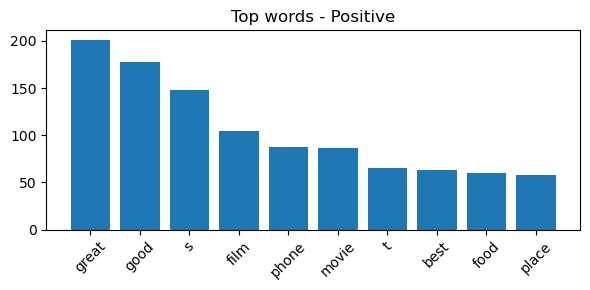

Negative [('t', 216), ('s', 112), ('bad', 100), ('movie', 96), ('phone', 80), ('like', 69), ('just', 66), ('food', 66), ('don', 64), ('time', 62)]


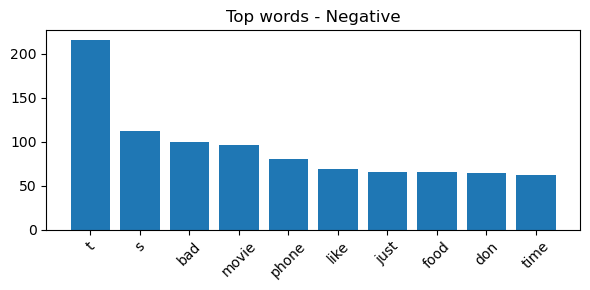

In [8]:
print("POSITIVE:\n", df[df.label == 1].text.head(5).to_string())
print("\nNEGATIVE:\n", df[df.label == 0].text.head(5).to_string())

for lab, name in [(1, "Positive"), (0, "Negative")]:
    words = " ".join(df[df.label == lab].clean_text).split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    top = Counter(words).most_common(10)
    print(name, top)
    plt.figure(figsize=(6, 3))
    plt.bar([w for w, _ in top], [c for _, c in top])
    plt.title(f"Top words - {name}")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()